# Tasks - Lab 4

### Task 3.1: Polymorphism & Ground-State Identification in Zirconia ($\mathrm{ZrO_2}$)

In [6]:
# ==============================================================================
# TASK 3.1: STUDENT STARTER CODE
# ==============================================================================
import pandas as pd
from mp_api.client import MPRester
import os
from dotenv import load_dotenv


# 1. Define fields to retrieve (enforce field projection)
# Required: material_id, formula_pretty, symmetry, density, band_gap,
#           formation_energy_per_atom, energy_above_hull, is_stable
target_fields = [
    "material_id",
    "formula_pretty",
    "symmetry",
    "density",
    "band_gap",
    "formation_energy_per_atom", "energy_above_hull", "is_stable"
]

# 2. Query summary endpoint within context manager for formula "ZrO2"
load_dotenv()
API_KEY = os.getenv("MP_API_KEY", None)
assert API_KEY is not None, "Please set the MP_API_KEY environment variable."
with MPRester(API_KEY) as mpr:
    docs_zro2 = mpr.materials.summary.search(formula="ZrO2", fields=target_fields)

print(f"Retrieved {len(docs_zro2)} records.")

# 3. Serialize SummaryDoc objects into a list of dictionaries
records = []
for doc in docs_zro2:
    # Extract scalar attributes and nested symmetry descriptors
    record = {
        "material_id": doc.material_id,
        "formula": doc.formula_pretty,
        "crystal_system": doc.symmetry.crystal_system,
        "space_group": doc.symmetry.number,
        "density": doc.density,
        "band_gap": doc.band_gap,
        "formation_energy_per_atom": doc.formation_energy_per_atom,
        "energy_above_hull": doc.energy_above_hull,
        "is_stable": doc.is_stable
    }
    records.append(record)

# 4. Construct DataFrame and sort by thermodynamic distance to hull
df_zro2 = pd.DataFrame(records)
df_zro2_sorted = df_zro2.sort_values(
    by="energy_above_hull"
).reset_index(drop=True)

print()
print("--- ZrO2 Polymorphs Catalog ---")
display(df_zro2_sorted)

# 5. Filter and inspect the true ground state (is_stable == True)
ground_state = df_zro2_sorted[df_zro2_sorted["is_stable"]]
print()
print("--- 0 K Thermodynamic Ground State ---")
display(ground_state)


✓ Retrieved 20 SummaryDoc documents in 0.3s

Retrieved 20 records.

--- ZrO2 Polymorphs Catalog ---


,material_id,formula,crystal_system,space_group,density,band_gap,formation_energy_per_atom,energy_above_hull,is_stable
0,mp-2858,ZrO2,Monoclinic,14,5.777331,3.5322,-3.813618,0.000000,True
1,mp-776404,ZrO2,Orthorhombic,61,5.781420,3.4629,-3.804120,0.009497,False
2,mp-1190186,ZrO2,Orthorhombic,61,6.034840,3.5794,-3.800361,0.013257,False
3,mp-556605,ZrO2,Orthorhombic,29,5.984315,3.7025,-3.796957,0.016661,False
4,mp-2574,ZrO2,Tetragonal,137,6.042620,3.8825,-3.786493,0.027125,False
5,mp-755089,ZrO2,Orthorhombic,62,5.707139,3.9596,-3.785647,0.027970,False
6,mp-755759,ZrO2,Orthorhombic,62,5.986052,3.2113,-3.784842,0.028776,False
7,mp-775910,ZrO2,Tetragonal,85,6.232380,3.3166,-3.766283,0.047335,False
8,mp-754403,ZrO2,Tetragonal,141,4.748267,3.7263,-3.765432,0.048186,False
9,mp-1565,ZrO2,Cubic,225,6.205969,3.1240,-3.757945,0.055673,False



--- 0 K Thermodynamic Ground State ---


,material_id,formula,crystal_system,space_group,density,band_gap,formation_energy_per_atom,energy_above_hull,is_stable
0,mp-2858,ZrO2,Monoclinic,14,5.777331,3.5322,-3.813618,0.0,True


### Task 3.2: Multi-Criteria Screening of Non-Toxic Solar Absorber Candidates

In [7]:
# ==============================================================================
# TASK 3.2: STUDENT STARTER CODE
# ==============================================================================
import pandas as pd
from mp_api.client import MPRester

# 1. Define negative filter (elements to strictly exclude)
toxic_elements = ["Pb", "Cd", "Hg", "As", "Tl"]

# 2. Define field projection list
target_fields = [
    "material_id",
    "formula_pretty",
    "symmetry",
    "band_gap",
    "formation_energy_per_atom",
    "energy_above_hull",
    "is_stable",
]

# 3. Query the summary endpoint applying chemical, electronic, and thermodynamic filters
with MPRester(API_KEY) as mpr:
    docs_absorbers = mpr.materials.summary.search(
        elements=["Cu", "S"],
        num_elements=3,
        exclude_elements=toxic_elements,
        band_gap=(1.0, 1.8),
        energy_above_hull=(0.0, 0.04),
        fields=target_fields,
    )

print(f"Total candidates matching criteria: {len(docs_absorbers)}")

# 4. Serialize summary documents into structured dictionary records
records = []
for doc in docs_absorbers:
    record = {
        "material_id": doc.material_id,
        "formula": doc.formula_pretty,
        "crystal_system": doc.symmetry.crystal_system,
        "space_group": doc.symmetry.number,
        "band_gap": doc.band_gap,
        "formation_energy_per_atom": doc.formation_energy_per_atom,
        "energy_above_hull": doc.energy_above_hull,
        "is_stable": doc.is_stable
    }
    records.append(record)

# 5. Build DataFrame, sort primarily by stability, and display top candidates
df_absorbers = pd.DataFrame(records)
df_absorbers_sorted = df_absorbers.sort_values(
    by=["energy_above_hull", "band_gap"], ascending=True
).reset_index(drop=True)

print()
print("--- Non-Toxic Solar Absorber Candidates (Cu-M-S Ternaries) ---")
display(df_absorbers_sorted)


✓ Retrieved 51 SummaryDoc documents in 1.5s

Total candidates matching criteria: 51

--- Non-Toxic Solar Absorber Candidates (Cu-M-S Ternaries) ---


,material_id,formula,crystal_system,space_group,band_gap,formation_energy_per_atom,energy_above_hull,is_stable
0,mp-3934,Cu3PS4,Orthorhombic,31,1.029900,-0.362578,0.000000,True
1,mp-3762,VCu3S4,Cubic,215,1.035800,-0.704041,0.000000,True
2,mp-16684,PrCuS2,Monoclinic,14,1.067800,-1.593450,0.000000,True
3,mp-10495,NdCuS2,Monoclinic,14,1.077600,-1.602239,0.000000,True
4,mp-1105187,CuPS3,Tetragonal,136,1.155500,-0.301249,0.000000,True
5,mp-5081,SmCuS2,Monoclinic,14,1.167800,-1.631051,0.000000,True
6,mp-5737,TbCuS2,Monoclinic,14,1.183200,-1.605268,0.000000,True
7,mp-4841,LaCuS2,Monoclinic,14,1.234500,-1.686311,0.000000,True
8,mp-1217848,Tb(CuS)3,Trigonal,148,1.341170,-1.010130,0.000000,True
9,mp-1225724,Dy(CuS)3,Trigonal,148,1.396667,-1.008077,0.000000,True


### Task 3.3: Phase Stability & Decomposition Analysis on the Convex Hull

In [8]:
# ==============================================================================
# TASK 3.3: STUDENT STARTER CODE
# ==============================================================================
import pandas as pd
from mp_api.client import MPRester

# 1. Define target fields for field projection
# Include: material_id, formula_pretty, symmetry, formation_energy_per_atom,
#          energy_above_hull, is_stable, decomposes_to
target_fields = [
    "material_id",
    "formula_pretty",
    "symmetry",
    "formation_energy_per_atom",
    "energy_above_hull",
    "is_stable",
    "decomposes_to",
]

# 2. Query closed binary system Ti-O
with MPRester(API_KEY) as mpr:
    docs_ti_o = mpr.materials.summary.search(chemsys="Ti-O", fields=target_fields)

print(f"Total Ti-O system entries retrieved: {len(docs_ti_o)}")

# 3. Serialize records into DataFrame
records = []
for doc in docs_ti_o:
    record = {
        "material_id": doc.material_id,
        "formula": doc.formula_pretty,
        "crystal_system": doc.symmetry.crystal_system,
        "space_group": doc.symmetry.number,
        "formation_energy_per_atom": doc.formation_energy_per_atom,
        "energy_above_hull": doc.energy_above_hull,
        "is_stable": doc.is_stable,
        "decomposes_to": doc.decomposes_to  # Retain raw decomposes_to reference
    }
    records.append(record)

df_ti_o = pd.DataFrame(records)
df_ti_o_sorted = df_ti_o.sort_values(
    by=["formula", "energy_above_hull"]
).reset_index(drop=True)

# 4. Isolate and display all ground-state phases lying on the Convex Hull
hull_phases = df_ti_o_sorted[df_ti_o_sorted["is_stable"]]
print()
print("--- Convex Hull Ground States in Ti-O System ---")
display(hull_phases[["material_id", "formula", "crystal_system", "space_group", "formation_energy_per_atom", "energy_above_hull"]])

# 5. Inspect decomposition products of an unstable phase
# Select the first record with energy_above_hull > 0.05
unstable_candidates = df_ti_o_sorted[df_ti_o_sorted["energy_above_hull"] > 0.05]
sample_unstable = unstable_candidates.iloc[0]

print()
print(f"--- Decomposition Pathway for Unstable Phase: {sample_unstable['material_id']} ({sample_unstable['formula']}) ---")
print(f"Driving Force (Energy Above Hull): {sample_unstable['energy_above_hull']:.4f} eV/atom")

# Iterate over decomposes_to and print decomposition products
for product in sample_unstable["decomposes_to"] or []:
    print(f"  -> {product}")


✓ Retrieved 124 SummaryDoc documents in 0.9s

Total Ti-O system entries retrieved: 124

--- Convex Hull Ground States in Ti-O System ---


,material_id,formula,crystal_system,space_group,formation_energy_per_atom,energy_above_hull
8,mp-1215,Ti2O,Trigonal,164,-2.035562,0.0
15,mp-458,Ti2O3,Trigonal,167,-3.303440,0.0
23,mp-2591,Ti3O,Trigonal,163,-1.569914,0.0
32,mp-8057,Ti3O5,Orthorhombic,63,-3.382134,0.0
52,mp-554098,Ti6O,Trigonal,163,-0.916695,0.0
65,mp-1071163,TiO,Hexagonal,189,-2.907956,0.0
78,mp-390,TiO2,Tetragonal,141,-3.508055,0.0



--- Decomposition Pathway for Unstable Phase: mp-684733 (Ti10O11) ---
Driving Force (Energy Above Hull): 0.1460 eV/atom
  -> material_id=AlphaID(mp-aaaaaarq) formula='Ti4 O6' amount=0.23809523809523814
  -> material_id=AlphaID(mp-aaaciyop) formula='Ti3 O3' amount=0.7619047619047619


### Task 3.4: Ingesting Pymatgen 3D Structures & Structure-Property Relationships

✓ Retrieved 322 SummaryDoc documents in 1.4s

Total SiO2 records retrieved: 322

--- SiO2 Polymorphs Catalog (Geometric & Physical Properties) ---


,material_id,formula,crystal_system,space_group,density,band_gap,energy_above_hull,is_stable,num_sites,cell_volume,volume_per_atom
0,mp-9258,SiO2,Cubic,205,4.415009,4.0091,0.577044,False,12,90.393773,7.532814
1,mp-10948,SiO2,Orthorhombic,60,4.216929,5.2559,0.259839,False,12,94.639796,7.886650
2,mp-32667,SiO2,Monoclinic,14,4.195638,5.3845,0.246879,False,18,142.680075,7.926671
3,mp-10064,SiO2,Cubic,225,4.146372,1.7393,1.277944,False,3,24.062559,8.020853
4,mp-6947,SiO2,Tetragonal,136,4.134212,5.0156,0.201711,False,6,48.266676,8.044446



Lowest Density Phase : mp-1365799 | Density = 0.5719008336494148 g/cm³ | V/atom = 58.15 Å³/atom
Highest Density Phase: mp-9258 | Density = 4.415008882327144 g/cm³ | V/atom = 7.53 Å³/atom


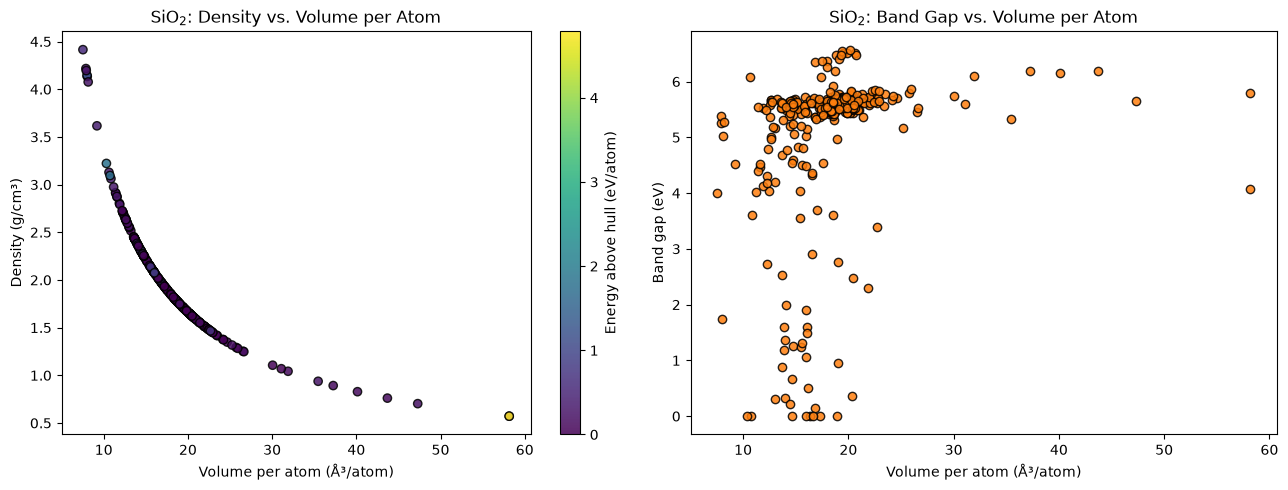

In [9]:
# ==============================================================================
# TASK 3.4: STUDENT STARTER CODE
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
from mp_api.client import MPRester
from pymatgen.core import Structure

# 1. Define fields for projection (MUST include "structure")
target_fields = [
    "material_id",
    "formula_pretty",
    "symmetry",
    "density",
    "band_gap",
    "energy_above_hull",
    "is_stable",
    "structure",
]

# 2. Query summary endpoint for formula="SiO2"
with MPRester(API_KEY) as mpr:
    docs_sio2 = mpr.materials.summary.search(formula="SiO2", fields=target_fields)

print(f"Total SiO2 records retrieved: {len(docs_sio2)}")

# 3. Extract scalar properties and derive geometric metrics from Structure objects
records = []
for doc in docs_sio2:
    struct: Structure = doc.structure

    num_sites = len(struct)
    cell_volume = struct.volume
    volume_per_atom = cell_volume / num_sites

    records.append({
        "material_id": doc.material_id,
        "formula": doc.formula_pretty,
        "crystal_system": doc.symmetry.crystal_system,
        "space_group": doc.symmetry.number,
        "density": doc.density,
        "band_gap": doc.band_gap,
        "energy_above_hull": doc.energy_above_hull,
        "is_stable": doc.is_stable,
        "num_sites": num_sites,
        "cell_volume": cell_volume,
        "volume_per_atom": volume_per_atom
    })

# 4. Construct DataFrame and sort by volume per atom
df_sio2 = pd.DataFrame(records)
df_sio2_sorted = df_sio2.sort_values(by="volume_per_atom", ascending=True).reset_index(drop=True)

print()
print("--- SiO2 Polymorphs Catalog (Geometric & Physical Properties) ---")
display(df_sio2_sorted.head())

# 5. Identify the least dense and most dense polymorphs
lowest_density_phase = df_sio2.loc[df_sio2["density"].idxmin()]
highest_density_phase = df_sio2.loc[df_sio2["density"].idxmax()]

print()
print(f"Lowest Density Phase : {lowest_density_phase['material_id']} | Density = {lowest_density_phase['density']} g/cm³ | V/atom = {lowest_density_phase['volume_per_atom']:.2f} Å³/atom")
print(f"Highest Density Phase: {highest_density_phase['material_id']} | Density = {highest_density_phase['density']} g/cm³ | V/atom = {highest_density_phase['volume_per_atom']:.2f} Å³/atom")

# 6. Generate Structure-Property Correlation Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)

# Panel 1: Density vs. Volume per Atom (color by energy_above_hull)
sc = axes[0].scatter(
    df_sio2["volume_per_atom"], df_sio2["density"],
    c=df_sio2["energy_above_hull"], cmap="viridis", edgecolor="k", alpha=0.85
)
fig.colorbar(sc, ax=axes[0], label="Energy above hull (eV/atom)")
axes[0].set_xlabel("Volume per atom (Å³/atom)")
axes[0].set_ylabel("Density (g/cm³)")
axes[0].set_title("SiO$_2$: Density vs. Volume per Atom")

# Panel 2: Band Gap vs. Volume per Atom
axes[1].scatter(
    df_sio2["volume_per_atom"], df_sio2["band_gap"],
    color="tab:orange", edgecolor="k", alpha=0.85
)
axes[1].set_xlabel("Volume per atom (Å³/atom)")
axes[1].set_ylabel("Band gap (eV)")
axes[1].set_title("SiO$_2$: Band Gap vs. Volume per Atom")

plt.tight_layout()
plt.show()
